# Prescribed displacements

This example imposes prescribed displacements on a plate, on a cylinder of five domains, and on a point of a plate, and checks the results against exact solutions.

The prescribed displacements of `Shell.add_point_pd`, `Shell.add_distr_pd_fixed_x` and `Shell.add_distr_pd_fixed_y` are imposed by a `MultiDomain`. With `pd_method='null-space'` they are imposed exactly: the prescriptions are linear constraints $\boldsymbol{G}\boldsymbol{c} = \boldsymbol{g}$ on the Ritz constants. Their solutions are $\boldsymbol{c} = \boldsymbol{c}_p + \boldsymbol{Z}\boldsymbol{q}$, with a particular solution $\boldsymbol{c}_p$ and a basis $\boldsymbol{Z}$ of the null space of $\boldsymbol{G}$, and the problem is solved for the reduced unknowns $\boldsymbol{q}$. With `pd_method='penalty'`, springs of large stiffness $k$ approximate the constraints, with an error of order $1/k$. See [Boundary conditions](../boundary_conditions.rst) and [Prescribed displacements imposed exactly](../multidomain_null_space.rst#prescribed-displacements-imposed-exactly).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import lb, solve
from structsolve.sparseutils import finalize_symmetric_matrix
from panels.shell import Shell
from panels.multidomain import MultiDomain
from panels.multidomain.cylinder import create_cylinder
from panels.multidomain.connections import fkCld_xcte


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))

## Patch test: a plate under an end shortening

An aluminium plate of $1 \times 0.6$ m, $h = 2$ mm, $E = 70$ GPa, $\nu = 0.3$, has the in-plane displacements free at its edges. It is shortened by $\delta = 1$ mm: $u = 0$ along $x = 0$ (`cte=True`, a constant prescription) and $u = -\delta$ along $x = a$. One point, the corner $(0, 0)$, has $v = 0$ to remove the rigid-body translation along $y$. The exact solution is a uniform uniaxial stress state:

$$
u = -\delta \frac{x}{a}, \qquad v = \nu \delta \frac{y}{a}, \qquad N_{xx} = -E h \frac{\delta}{a}, \qquad N_{yy} = 0,
$$

which the approximation functions contain, so that the Ritz solution must reproduce it. A single shell is wrapped in an assembly without connections, `conn=[]`, and `MultiDomain.linear_static` returns the Ritz constants with the prescribed displacements.

In [2]:
E, NU, h, delta = 70e9, 0.3, 2e-3, 1e-3
p = Shell(a=1., b=0.6, m=6, n=6, model='plate_clpt_donnell', stack=[0],
          plyt=h, laminaprop=(E, NU))
for edge in ('x1', 'x2', 'y1', 'y2'):
    setattr(p, edge + 'u', 1.)
    setattr(p, edge + 'v', 1.)
p.add_distr_pd_fixed_x(0., ku=1., funcu=lambda y: 0., cte=True)
p.add_distr_pd_fixed_x(p.a, ku=1., funcu=lambda y: -delta, cte=False)
p.add_point_pd(0., 0., 0, None, 1., 0., 0, None)
md = MultiDomain([p], conn=[], pd_method='null-space')
c = md.linear_static()
cp = c[p.col_start:p.col_end]
mesh, f = p.uvw(cp, gridx=21, gridy=13)
X, Y, u, v = mesh['Xs'], mesh['Ys'], f['u'].copy(), f['v'].copy()
_, f = p.stress(cp, gridx=21, gridy=13)
Nxx, Nyy = f['Nxx'].copy(), f['Nyy'].copy()
print('largest error of u: %.2e m, of v: %.2e m'
      % (np.abs(u + delta*X/p.a).max(), np.abs(v - NU*delta*Y/p.a).max()))
print('Nxx from %.4f to %.4f N/m, largest |Nyy| %.2e N/m'
      % (Nxx.min(), Nxx.max(), np.abs(Nyy).max()))
results_table([
    ('$u$ at $(a, b)$ (m)', u[-1, -1], -delta, 'exact solution'),
    ('$v$ at $(a, b)$ (m)', v[-1, -1], NU*delta*p.b/p.a, 'exact solution'),
    ('mean $N_{xx}$ (N/m)', Nxx.mean(), -E*h*delta/p.a, 'exact solution'),
])

largest error of u: 8.94e-19 m, of v: 4.04e-18 m
Nxx from -140000.0000 to -140000.0000 N/m, largest |Nyy| 5.97e-09 N/m


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| $u$ at $(a, b)$ (m) | -0.001 | -0.001 | +4.34e-16 | exact solution |
| $v$ at $(a, b)$ (m) | 0.00018 | 0.00018 | +2.24e-14 | exact solution |
| mean $N_{xx}$ (N/m) | -140000 | -140000 | +0.00e+00 | exact solution |

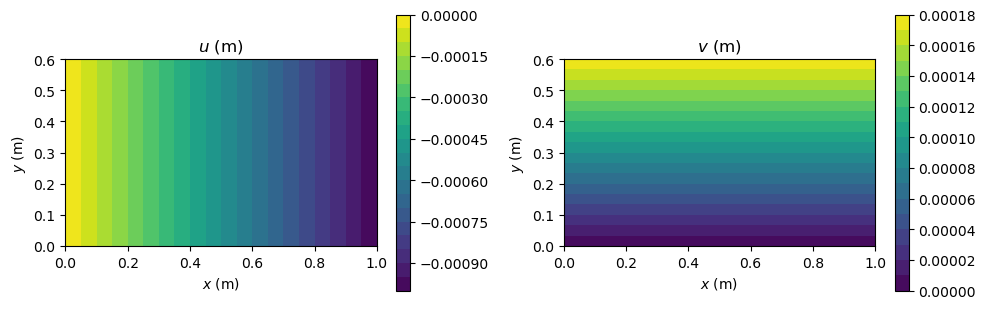

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, field, title in zip(axes, (u, v), ('$u$ (m)', '$v$ (m)')):
    cf = ax.contourf(X, Y, field, levels=20, cmap='viridis')
    fig.colorbar(cf, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('$x$ (m)')
    ax.set_ylabel('$y$ (m)')
    ax.set_aspect('equal')
fig.tight_layout()
plt.show()

## A cylinder under an end shortening

A laminated cylinder of five domains, `create_cylinder`, with $r = 0.25$ m, length 0.5 m, laminate $[0/45/-45/90/-45/45]$ of plies of 0.125 mm, is compressed in two ways. First a uniform axial load $N_{xx} = -100$ N/m is applied at $x = a$. Then the end shortening $\delta$ that this load produces is prescribed at $x = a$. The two give the same pre-buckling state, and the total reaction force at the shortened end, `MultiDomain.reaction_resultant`, equals the applied load $N_{xx} 2\pi r$. The critical load of the displacement control is slightly higher, since the prescribed end shortening keeps the end section plane.

The connections are imposed here with the null-space method. The reference of the critical load under the axial load is the regression value of the penalty method of the panels unit test `tests/multidomain/test_cylinder.py`; the unit test `tests/multidomain/test_null_space_pd.py` checks the null-space result against it within 0.2%.

In [4]:
LAMINAPROP = (142.5e9, 8.7e9, 0.28, 5.1e9, 5.1e9, 5.1e9)


def cylinder(pd_method):
    md, conns = create_cylinder(height=0.5, r=0.25, plyt=0.125e-3,
                                stack=[0, 45, -45, 90, -45, 45],
                                laminaprop=LAMINAPROP, npanels=5, m=8, n=12)
    md = MultiDomain(md.panels, conns, pd_method=pd_method)
    for p in md.panels:
        p.x2u = 1  # u released at x = a, loaded or prescribed there
    return md


Nxx = -100.
md = cylinder('null-space')
for p in md.panels:
    p.add_distr_load_fixed_x(p.a, lambda y: Nxx, None, None)
eig_N, modes_N = md.linear_buckling(num_eigvalues=3)
c_N = md.linear_static()
p0 = md.panels[0]
delta = -p0.uvw(c_N[p0.col_start:p0.col_end], gridx=7, gridy=5)[1]['u'][0, -1]
print('axial load: critical Nxx = %.3f N/m, end shortening %.6e m'
      % (Nxx*eig_N[0], delta))

md_d = cylinder('null-space')
for p in md_d.panels:
    p.add_distr_pd_fixed_x(p.a, ku=1., funcu=lambda y: -delta, cte=False)
eig_d, modes_d = md_d.linear_buckling(num_eigvalues=3)
c_d = md_d.linear_static()
F = md_d.reaction_resultant(c_d, [(p, 'x', p.a) for p in md_d.panels],
                            NLgeom=False)
print('end shortening: critical multiplier %.6f, ratio to the axial load '
      '%.5f' % (eig_d[0], eig_d[0]/eig_N[0]))
print('largest difference of the pre-buckling Ritz constants: %.2e of the '
      'largest' % (np.abs(c_d - c_N).max()/np.abs(c_N).max()))
results_table([
    ('critical $N_{xx}$, axial load (N/m)', Nxx*eig_N[0], -47162.406,
     'regression value (penalty), `test_cylinder.py`'),
    ('axial reaction at $x = a$ (N)', F[0], Nxx*2*np.pi*0.25,
     'equilibrium, $N_{xx} 2 \\pi r$'),
])

axial load: critical Nxx = -47220.276 N/m, end shortening 1.471929e-06 m


end shortening: critical multiplier 490.159556, ratio to the axial load 1.03803
largest difference of the pre-buckling Ritz constants: 1.91e-08 of the largest


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| critical $N_{xx}$, axial load (N/m) | -47220.3 | -47162.4 | -1.23e-03 | regression value (penalty), `test_cylinder.py` |
| axial reaction at $x = a$ (N) | -157.08 | -157.08 | +4.52e-15 | equilibrium, $N_{xx} 2 \pi r$ |

With the penalty method the springs of `fkCld_xcte`, of stiffness $k$ per unit length, are added by the user to the stiffness matrix, and the prescribed value enters $\boldsymbol{F}_{ext}$ as $k u_p$. The connections of the domains are still exact, by the null space of `MultiDomain.reduce`. The critical load converges to that of the null-space method as $k$ increases, with an error proportional to $1/k$:

k = 1e+02 A11: relative error of the critical load 1.306e-02


k = 1e+03 A11: relative error of the critical load 1.281e-03


k = 1e+04 A11: relative error of the critical load 1.279e-04


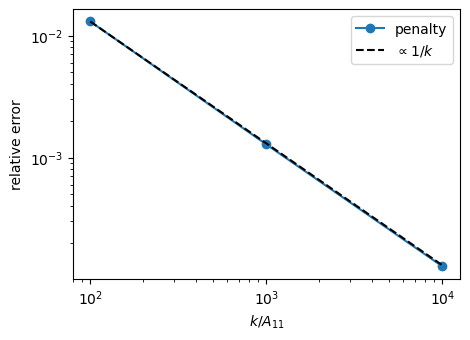

In [5]:
factors = [1e2, 1e3, 1e4]
errors = []
for factor in factors:
    md_p = cylinder('penalty')
    size = md_p.get_size()
    k = factor*md_p.panels[0].lam.ABD[0, 0]
    kCp = 0.
    for p in md_p.panels:
        p.add_distr_pd_fixed_x(p.a, ku=k, funcu=lambda y: -delta, cte=False)
        kCp = kCp + fkCld_xcte(k, 0., 0., p, p.a, size, p.row_start,
                               p.col_start)
    K = md_p.calc_kC(silent=True) + finalize_symmetric_matrix(kCp)
    c = md_p.expand(solve(md_p.reduce(K), md_p.reduce(md_p.calc_fext()),
                          silent=True))
    eig, _ = lb(md_p.reduce(K), md_p.reduce(md_p.calc_kG(c=c, silent=True)),
                silent=True, num_eigvalues=3)
    errors.append(eig[0]/eig_d[0] - 1)
    print('k = %.0e A11: relative error of the critical load %.3e'
          % (factor, errors[-1]))
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.loglog(factors, errors, 'o-', label='penalty')
ax.loglog(factors, errors[0]*factors[0]/np.array(factors), 'k--',
          label='$\\propto 1/k$')
ax.set_xlabel('$k/A_{11}$')
ax.set_ylabel('relative error')
ax.legend()
plt.show()

## A point supported by penalty springs

Without an assembly, a point of a `Shell` is supported by the penalty springs of `Shell.calc_stiffness_point_constraint`, added to the stiffness matrix. Here the center of a square aluminium plate of 1 m, $h = 2$ mm, simply supported, is supported by a spring of $10^{12}$ N/m in $w$. A unit point force at the same point then produces almost no deflection there; without the spring the plate deflects freely.

In [6]:
s = Shell(a=1., b=1., r=None, stack=[0], plyt=2e-3, laminaprop=(71e9, 0.33),
          model='plate_clpt_donnell', m=6, n=6)
s.add_point_load(0.5, 0.5, 0, 0, 1.)
kC = s.calc_kC()
xs, ys = np.array([0.5]), np.array([0.5])
c = solve(kC + s.calc_stiffness_point_constraint(0.5, 0.5, u=False, v=False,
                                                 kuvw=1e12),
          s.calc_fext(), silent=True)
w_constrained = s.uvw(c, xs=xs, ys=ys)[1]['w'][0]
c = solve(kC, s.calc_fext(), silent=True)
w_free = s.uvw(c, xs=xs, ys=ys)[1]['w'][0]
print('w at the center: %.3e m with the spring, %.3e m without; ratio %.2e'
      % (w_constrained, w_free, w_constrained/w_free))

w at the center: 1.000e-12 m with the spring, 1.972e-04 m without; ratio 5.07e-09
